In [ ]:
%pip install transformers librosa torch scikit-learn soundfile

In [2]:
from transformers import Wav2Vec2Processor, Wav2Vec2Model
import whisper

# Wav2Vec2 (for emotion)
processor = Wav2Vec2Processor.from_pretrained("facebook/wav2vec2-base")
wav2vec_model = Wav2Vec2Model.from_pretrained("facebook/wav2vec2-base")

# Whisper (for speech-to-text)
whisper_model = whisper.load_model("base")

## **Load dataset correctly**

In [3]:
import os

data = []
labels = []

dataset_path = "data/IESC"  # Indian Emotional Speech Corpora (English)

for speaker in os.listdir(dataset_path):
    speaker_path = os.path.join(dataset_path, speaker)
    
    if os.path.isdir(speaker_path):
        for emotion in os.listdir(speaker_path):
            emotion_path = os.path.join(speaker_path, emotion)
            
            if os.path.isdir(emotion_path):
                for file in os.listdir(emotion_path):
                    if file.endswith(".wav"):
                        file_path = os.path.join(emotion_path, file)
                        
                        data.append(file_path)
                        labels.append(emotion.lower())

print("Total samples:", len(data))
print("Unique emotions:", set(labels))

Total samples: 600
Unique emotions: {'neutral', 'sad', 'fear', 'anger', 'happy'}


In [4]:
from collections import Counter

print(Counter(labels))

Counter({'anger': 120, 'fear': 120, 'happy': 120, 'neutral': 120, 'sad': 120})


## **Converting to Telephonic Audio**

In [5]:
import librosa
import numpy as np
import soundfile as sf
from scipy.signal import butter, lfilter

# Bandpass filter (300–3400 Hz)
def bandpass_filter(data, sr, lowcut=300, highcut=3400):
    nyquist = 0.5 * sr
    low = lowcut / nyquist
    high = highcut / nyquist
    
    b, a = butter(4, [low, high], btype='band')
    return lfilter(b, a, data)

def convert_to_telephone(input_path, output_path):
    # Load original
    audio, sr = librosa.load(input_path, sr=None)
    
    # Resample to 8kHz
    audio_8k = librosa.resample(audio, orig_sr=sr, target_sr=8000)
    
    # Apply bandpass filter
    filtered_audio = bandpass_filter(audio_8k, 8000)
    
    # Save
    sf.write(output_path, filtered_audio, 8000)
    
    return filtered_audio

In [6]:
import os

input_file = data[0]  # test with one file first
output_file = "telephone_sample.wav"

tele_audio = convert_to_telephone(input_file, output_file)

print("Converted successfully")

Converted successfully


In [7]:
import matplotlib.pyplot as plt

def plot_spectrogram(audio, sr, title):
    plt.figure(figsize=(10, 4))
    S = librosa.stft(audio)
    S_db = librosa.amplitude_to_db(abs(S))
    
    librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='hz')
    plt.colorbar()
    plt.title(title)
    plt.tight_layout()
    plt.show()

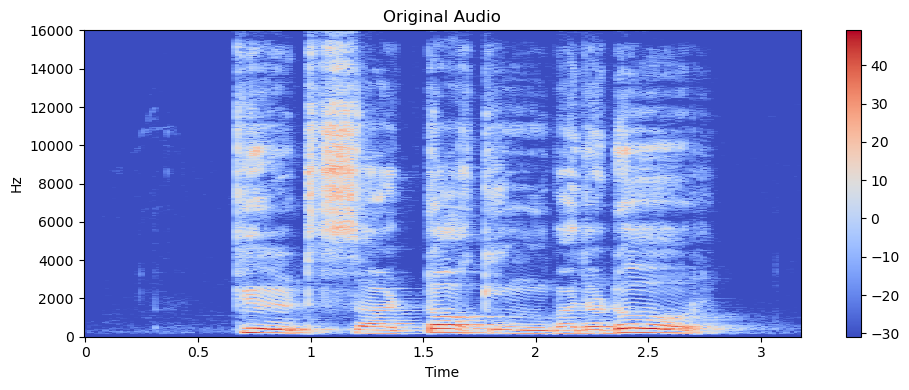

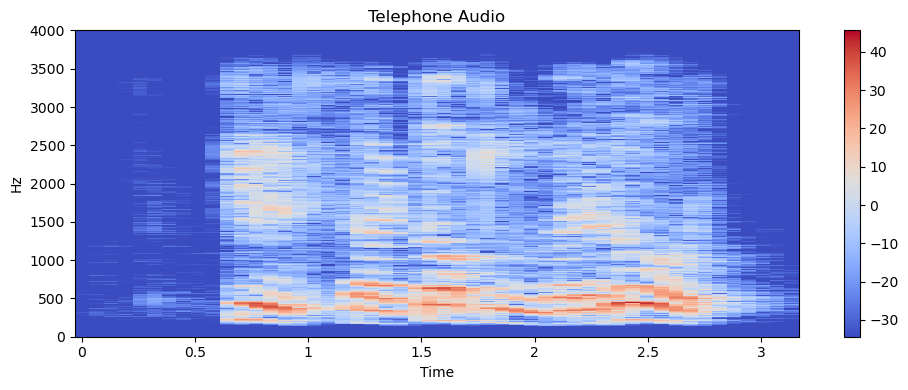

In [8]:
import librosa.display

# Load original
orig_audio, orig_sr = librosa.load(input_file, sr=None)

# Load telephonic
tel_audio, tel_sr = librosa.load(output_file, sr=None)

# Plot
plot_spectrogram(orig_audio, orig_sr, "Original Audio")
plot_spectrogram(tel_audio, tel_sr, "Telephone Audio")

## **Extracting Features**

In [9]:
import librosa
import torch
import numpy as np

def extract_features(file_path):
    audio, sr = librosa.load(file_path, sr=8000)
    
    # Upsample for wav2vec
    audio_16k = librosa.resample(audio, orig_sr=8000, target_sr=16000)
    
    # Wav2Vec features
    inputs = processor(audio_16k, sampling_rate=16000, return_tensors="pt", padding=True)
    
    with torch.no_grad():
        outputs = model(**inputs)
    
    wav2vec_feat = outputs.last_hidden_state.mean(dim=1).squeeze().numpy()
    
    # MFCC features
    mfcc = librosa.feature.mfcc(y=audio, sr=8000, n_mfcc=40)
    mfcc_feat = np.mean(mfcc, axis=1)
    
    # Combine
    combined = np.concatenate([wav2vec_feat, mfcc_feat])
    
    return combined

In [10]:
import librosa
import torch
import numpy as np

def extract_features(file_path):
    audio, sr = librosa.load(file_path, sr=8000)
    
    # convert to 16kHz
    audio_16k = librosa.resample(audio, orig_sr=8000, target_sr=16000)
    
    inputs = processor(audio_16k, sampling_rate=16000, return_tensors="pt", padding=True)
    
    with torch.no_grad():
        outputs = wav2vec_model(**inputs)
    
    features = outputs.last_hidden_state.mean(dim=1)
    
    return features.squeeze().numpy()

## **Convert dataset to features**

In [11]:
X = []
y = []

for file, label in zip(data, labels):
    try:
        features = extract_features(file)  # telephonic file path
        X.append(features)
        y.append(label)
    except:
        print("Error:", file)

print("Feature extraction done")

Feature extraction done


## **Encode labels**

In [12]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_encoded = le.fit_transform(y)

## **Train model**

In [13]:
# Copy X, y from before

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42
)

# Scale
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Tuned model
clf = RandomForestClassifier(
    n_estimators=500,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

clf.fit(X_train, y_train)

RandomForestClassifier(max_depth=20, min_samples_leaf=2, min_samples_split=5,
                       n_estimators=500, random_state=42)

## **Evaluate**

In [14]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8
              precision    recall  f1-score   support

           0       0.76      0.90      0.83        21
           1       0.95      0.73      0.83        26
           2       0.73      0.79      0.76        24
           3       0.75      0.86      0.80        28
           4       0.88      0.71      0.79        21

    accuracy                           0.80       120
   macro avg       0.81      0.80      0.80       120
weighted avg       0.81      0.80      0.80       120



## **Trying new Methods**

In [15]:
import torch
import torch.nn as nn

X_tensor = torch.tensor(X, dtype=torch.float32)
y_tensor = torch.tensor(y_encoded, dtype=torch.long)

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_tensor, y_tensor, test_size=0.2, random_state=42)

In [17]:
class EmotionNN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256),
            nn.Dropout(0.4),
            
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            
            nn.Linear(128, 5)
        )

    def forward(self, x):
        return self.model(x)

In [18]:
model_nn = EmotionNN(X_train.shape[1])

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_nn.parameters(), lr=0.001)

for epoch in range(30):
    outputs = model_nn(X_train)
    loss = criterion(outputs, y_train)
    
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    if epoch % 5 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item()}")

Epoch 0, Loss: 1.6205240488052368
Epoch 5, Loss: 1.047589659690857
Epoch 10, Loss: 0.7450219392776489
Epoch 15, Loss: 0.49437522888183594
Epoch 20, Loss: 0.3234032690525055
Epoch 25, Loss: 0.2025984227657318


In [19]:
with torch.no_grad():
    preds = model_nn(X_test)
    y_pred = torch.argmax(preds, dim=1)

from sklearn.metrics import accuracy_score

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8166666666666667


## **Speech to Text**

In [ ]:
%pip install openai-whisper nltk

## **Speech-to-text**

In [21]:
import whisper
import librosa

whisper_model = whisper.load_model("base")

def speech_to_text(file_path):
    audio, sr = librosa.load(file_path, sr=16000)
    
    result = whisper_model.transcribe(audio)
    
    return result["text"]

In [22]:
file = data[0]   # your telephonic audio file

text = speech_to_text(file)

print("Text:", text)

Text:  Kids are talking by the door.


In [ ]:
%pip install nltk

## **Keyword extraction code**

In [24]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

nltk.download('punkt')
nltk.download('stopwords')

def extract_keywords(text):
    words = word_tokenize(text.lower())
    
    stop_words = set(stopwords.words('english'))
    
    keywords = [word for word in words if word.isalnum() and word not in stop_words]
    
    return keywords

In [25]:
text = speech_to_text(data[0])

keywords = extract_keywords(text)

print("Full Text:", text)
print("Keywords:", keywords)

Full Text:  Kids are talking by the door.
Keywords: ['kids', 'talking', 'door']


## **Combine Emotion + Keywords**

In [26]:
# Emotion prediction
emotion_pred = clf.predict([X_test[0]])

emotion_label = le.inverse_transform(emotion_pred)   # or your feature input

# Speech to text
text = speech_to_text(data[0])

# Keywords
keywords = extract_keywords(text)

print("Emotion:", emotion_label[0])
print("Keywords:", keywords)

Emotion: happy
Keywords: ['kids', 'talking', 'door']


## **Handling Hindi Language audio**

In [27]:
import os

hindi_data = []
hindi_labels = []

base_path = "data/hindi"  # Hindi emotional speech dataset

for speaker in os.listdir(base_path):
    speaker_path = os.path.join(base_path, speaker)
    
    if os.path.isdir(speaker_path):
        for session in os.listdir(speaker_path):
            session_path = os.path.join(speaker_path, session)
            
            if os.path.isdir(session_path):
                for emotion in os.listdir(session_path):
                    emotion_path = os.path.join(session_path, emotion)
                    
                    if os.path.isdir(emotion_path):
                        for file in os.listdir(emotion_path):
                            if file.endswith(".wav"):
                                file_path = os.path.join(emotion_path, file)
                                
                                hindi_data.append(file_path)
                                hindi_labels.append(emotion.lower())

print("Total Hindi samples:", len(hindi_data))
print("Emotions:", set(hindi_labels))

Total Hindi samples: 3200
Emotions: {'disgust', 'neutral', 'sad', 'fear', 'surprise', 'anger', 'happy', 'sarcastic'}


In [28]:
valid_labels = ['neutral', 'anger', 'happy', 'sad', 'fear']

filtered_data = []
filtered_labels = []

for i in range(len(hindi_labels)):
    label = hindi_labels[i]
    
    if label in valid_labels:
        filtered_data.append(hindi_data[i])
        filtered_labels.append(label)

print("Filtered labels:", set(filtered_labels))

Filtered labels: {'neutral', 'sad', 'fear', 'anger', 'happy'}


In [29]:
telephonic_files = []

for i, file in enumerate(filtered_data):
    out_file = f"temp_hindi_{i}.wav"
    
    convert_to_telephone(file, out_file)
    telephonic_files.append(out_file)

In [30]:
X_hindi = []

for file in telephonic_files:
    feat = extract_features(file)
    X_hindi.append(feat)

In [31]:
X_hindi = scaler.transform(X_hindi)

In [32]:
y_pred = clf.predict(X_hindi)

In [33]:
y_true = le.transform(filtered_labels)

from sklearn.metrics import accuracy_score
print("Hindi Accuracy:", accuracy_score(y_true, y_pred))

Hindi Accuracy: 0.2985


## **REAL TIME AUDIO**

In [ ]:
%pip install sounddevice scipy

## **Record audio from microphone**

In [35]:
import sounddevice as sd
from scipy.io.wavfile import write

def record_audio(filename="input.wav", duration=5, fs=16000):
    print("Recording...")
    audio = sd.rec(int(duration * fs), samplerate=fs, channels=1)
    sd.wait()
    
    write(filename, fs, audio)
    print("Recording complete")
    
    return filename

## **Convert to telephonic**

In [36]:
tel_file = "telephonic.wav"
convert_to_telephone(input_file, tel_file)

array([ 1.80974329e-04,  1.45366329e-04, -3.65395121e-04, ...,
       -5.99370011e-04, -1.57422054e-04, -8.67993115e-05])

## **Emotion prediction**

In [37]:
def predict_emotion(file):
    feat = extract_features(file)
    
    feat = scaler.transform([feat])
    
    pred = clf.predict(feat)
    
    return le.inverse_transform(pred)[0]

## **Speech-to-text**

In [38]:
def get_text(file):
    return speech_to_text(file)

## **Keywords**

In [39]:
def get_keywords(text):
    return extract_keywords(text)

## **FULL PIPELINE**

In [90]:
# Record
input_file = record_audio()

# Convert
tel_file = "telephonic.wav"
convert_to_telephone(input_file, tel_file)

# Emotion
emotion = predict_emotion(tel_file)

# Text
text = get_text(tel_file)

# Keywords
keywords = get_keywords(text)

# Output
print("\n--- FINAL OUTPUT ---")
print("Emotion:", emotion)
print("Keywords:", keywords)

Recording...
Recording complete



--- FINAL OUTPUT ---
Emotion: neutral
Keywords: ['today', 'news']


## **Results**

In [43]:
from sklearn.model_selection import train_test_split

X_train, X_test_main, y_train, y_test_main = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42
)

In [44]:
X_test_main = scaler.transform(X_test_main)

In [45]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_main = clf.predict(X_test_main)

print("Main Accuracy:", accuracy_score(y_test_main, y_pred_main))
print(classification_report(y_test_main, y_pred_main, target_names=le.classes_))

Main Accuracy: 0.8
              precision    recall  f1-score   support

       anger       0.76      0.90      0.83        21
        fear       0.95      0.73      0.83        26
       happy       0.73      0.79      0.76        24
     neutral       0.75      0.86      0.80        28
         sad       0.88      0.71      0.79        21

    accuracy                           0.80       120
   macro avg       0.81      0.80      0.80       120
weighted avg       0.81      0.80      0.80       120



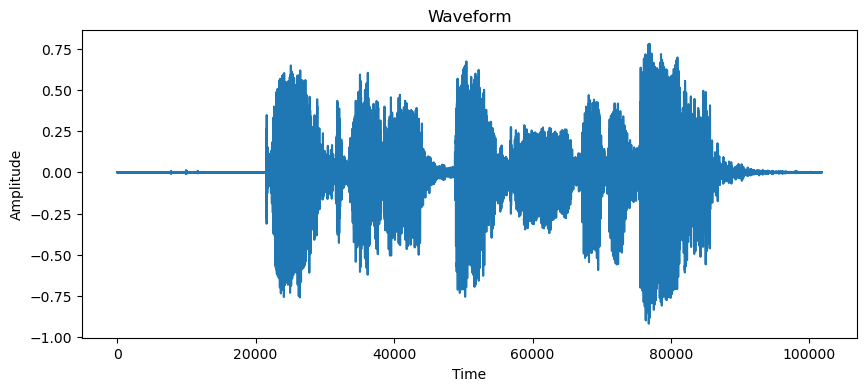

In [46]:
import librosa
import matplotlib.pyplot as plt

def plot_waveform(file):
    audio, sr = librosa.load(file, sr=None)
    
    plt.figure(figsize=(10,4))
    plt.plot(audio)
    plt.title("Waveform")
    plt.xlabel("Time")
    plt.ylabel("Amplitude")
    plt.show()

# Example
plot_waveform(data[0])

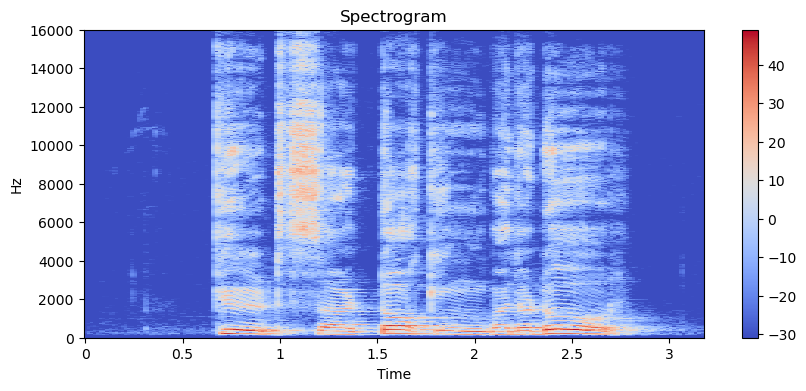

In [47]:
import librosa.display

def plot_spectrogram(file):
    audio, sr = librosa.load(file, sr=None)
    
    S = librosa.stft(audio)
    S_db = librosa.amplitude_to_db(abs(S))
    
    plt.figure(figsize=(10,4))
    librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='hz')
    plt.colorbar()
    plt.title("Spectrogram")
    plt.show()

plot_spectrogram(data[0])

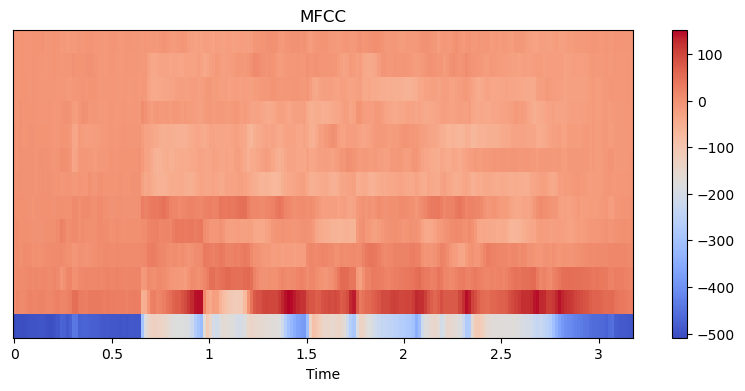

In [48]:
def plot_mfcc(file):
    audio, sr = librosa.load(file, sr=None)
    
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=13)
    
    plt.figure(figsize=(10,4))
    librosa.display.specshow(mfcc, sr=sr, x_axis='time')
    plt.colorbar()
    plt.title("MFCC")
    plt.show()

plot_mfcc(data[0])

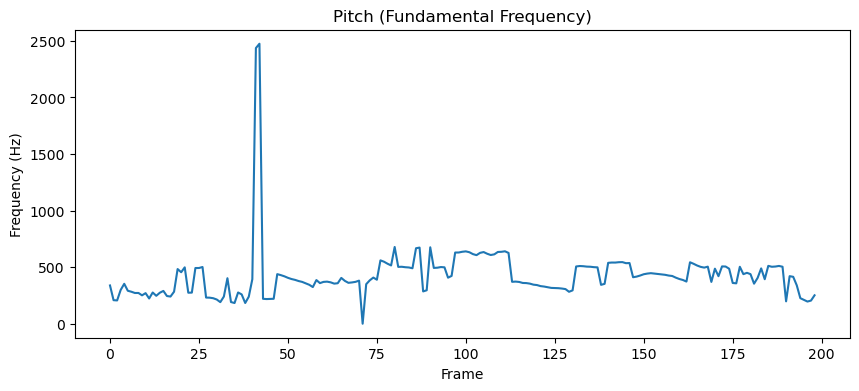

In [49]:
import numpy as np

def plot_pitch(file):
    audio, sr = librosa.load(file, sr=None)
    
    pitches, magnitudes = librosa.piptrack(y=audio, sr=sr)
    
    pitch = []
    for i in range(pitches.shape[1]):
        index = magnitudes[:, i].argmax()
        pitch.append(pitches[index, i])
    
    plt.figure(figsize=(10,4))
    plt.plot(pitch)
    plt.title("Pitch (Fundamental Frequency)")
    plt.xlabel("Frame")
    plt.ylabel("Frequency (Hz)")
    plt.show()

plot_pitch(data[0])

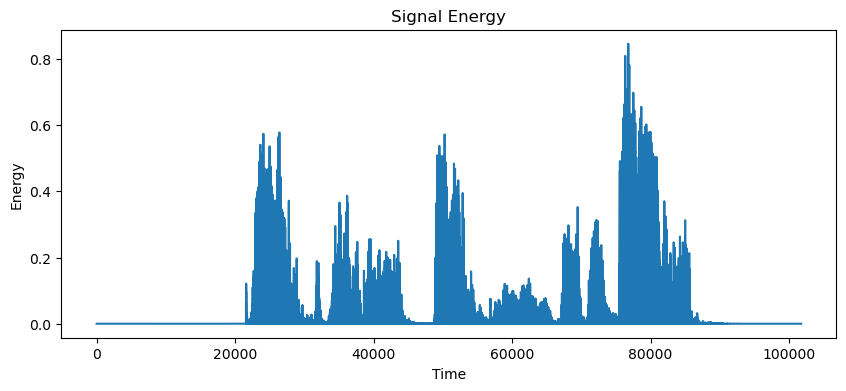

In [50]:
def plot_energy(file):
    audio, sr = librosa.load(file, sr=None)
    
    energy = audio**2
    
    plt.figure(figsize=(10,4))
    plt.plot(energy)
    plt.title("Signal Energy")
    plt.xlabel("Time")
    plt.ylabel("Energy")
    plt.show()

plot_energy(data[0])